### Testing GraphBuilder

#### Node classification - One Graph - Cora

In [18]:
from torch_geometric import datasets
from torch_geometric.transforms import GDC
from torch_geometric.utils import to_networkx
from rewiring.model.GCN import GCN
from torch_geometric.nn import GIN
from rewiring.pipeline.SingleGraphNodeClassificationPipeline import SingleGraphNodeClassificationPipeline

from rewiring.transform.AddRandomEdges import AddRandomEdges
from rewiring.transform.ReduceDiameter import ReduceDiameter


import torch
import networkx as nx
import numpy as np
import logging

# logging.basicConfig(level=logging.INFO)

mylist = []

# transform = ReduceDiameter(max_diam=5)
transform = AddRandomEdges(min_density=0.2)
transform = None
# transform = GDC()
# dset = datasets.Planetoid(root=f'./../res/datasets/Planetoid', name='CiteSeer', pre_transform=transform)
dset = datasets.Planetoid(root=f'./../res/datasets/Planetoid', name='Cora', pre_transform=transform)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

for _ in range(5):

    model = GIN(in_channels=dset.num_features,
                hidden_channels=16,
                num_layers=2,
                out_channels=dset.num_classes)

    model = GCN(num_classes=dset.num_classes, 
                num_features=dset.num_features, 
                hidden_size=16)

    model.set_classification_task(task='node')
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)

    criterion = torch.nn.CrossEntropyLoss()
    criterion = torch.nn.NLLLoss()

    pipeline = SingleGraphNodeClassificationPipeline(
        device=device,
        model=model,
        criterion=criterion,
        optimizer=optimizer
    )

    pipeline.set_masks(data=dset)

    _, _, acc = pipeline.train_validate(
        data=dset[0],
        epochs=200,
        log=True
    )
    mylist.append(np.array(acc).max() * 100)

print(f'${np.average(mylist):.1f}\\pm{np.std(mylist):.0f}$')

Epoch: [1/200]         Training loss: 2.0016         Validation loss: 1.9806         Accuracy: 0.0572
Epoch: [2/200]         Training loss: 1.9803         Validation loss: 1.9568         Accuracy: 0.0590
Epoch: [3/200]         Training loss: 1.9579         Validation loss: 1.9296         Accuracy: 0.0904
Epoch: [4/200]         Training loss: 1.9321         Validation loss: 1.8973         Accuracy: 0.2915
Epoch: [5/200]         Training loss: 1.9013         Validation loss: 1.8588         Accuracy: 0.4502
Epoch: [6/200]         Training loss: 1.8642         Validation loss: 1.8145         Accuracy: 0.4410
Epoch: [7/200]         Training loss: 1.8211         Validation loss: 1.7672         Accuracy: 0.4077
Epoch: [8/200]         Training loss: 1.7743         Validation loss: 1.7181         Accuracy: 0.4244
Epoch: [9/200]         Training loss: 1.7258         Validation loss: 1.6682         Accuracy: 0.4373
Epoch: [10/200]         Training loss: 1.6761         Validation loss: 1.6177     

#### Node Classification - Multiple Graphs - LRGB PascalVOC-SP

In [ ]:
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch_geometric.nn.conv import GCNConv
from torch_geometric.loader import DataLoader
from torch_geometric.datasets import LRGBDataset

from rewiring.model.GCN import GCN
from rewiring.transform.AddRandomEdges import AddRandomEdges
from rewiring.transform.ReduceDiameter import ReduceDiameter
from rewiring.pipeline.NodeClassificationPipeline import NodeClassifiactionPipeline

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

batch_size = 64
# transform = ReduceDiameter(max_diam=200)
# transform = AddRandomEdges(min_density=0.25)
transform = None

# Load the dataset
print("Loading and transforming training dataset...")
train_dataset = LRGBDataset(root=f'./../res/datasets/LRGB', name='PascalVOC-SP', transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = LRGBDataset(root=f'./../res/datasets/LRGB', name='PascalVOC-SP', split='val')
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = LRGBDataset(root=f'./../res/datasets/LRGB', name='PascalVOC-SP', split='test')
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Create the model
num_features = train_dataset.num_features
num_classes = train_dataset.num_classes
hidden_size = 64
model = GCN(num_classes=num_classes,
            num_features=num_features,
            hidden_size=hidden_size).to(device)
model.set_classification_task('node')

# Set the loss function and optimizer
criterion = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

pipeline = NodeClassifiactionPipeline(
    device = device,
    model=model,
    criterion=criterion,
    optimizer=optimizer
)

num_epochs = 3
print("Started training...")
pipeline.train_validate(
    train_data=train_loader, 
    val_data=val_loader, 
    epochs=num_epochs, 
    log=True
)
print("Training finished!")

print("Starting testing...")
model.eval()
correct = 0
epoch_test_loss = []
sum = len(test_loader.dataset.y)
print(f'Test element count: {sum}')
for batch in test_loader:
    batch = batch.to(device)
    with torch.no_grad():
        out = model(batch.x, batch.edge_index)
        test_loss = criterion(out, batch.y)
        epoch_test_loss.append(test_loss.item())
        _, pred = torch.max(out.data, 1)
        correct += (pred == batch.y).float().sum().item()

acc = correct / sum
test_loss = np.array(epoch_test_loss).mean().item()

print(f"""Loss: {test_loss:.4f} \
        Accuracy: {acc:.4f}""")

#### Graph Classification - Proteins, Mutag

In [ ]:
from torch_geometric import datasets
from torch_geometric.loader import DataLoader
from torch_geometric.transforms import TwoHop
from rewiring.model.GCN import GCN
from rewiring.TrainValTestSplitter import TrainValTestSplitter
from rewiring.transform.ReduceDiameter import ReduceDiameter
from rewiring.transform.AddRandomEdges import AddRandomEdges
from rewiring.pipeline.GraphClassificationPipeline import GraphClassificationPipeline

import torch
import numpy as np
import logging

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

transform = None
# transform = AddRandomEdges(min_density=0.4)
# transform = ReduceDiameter(max_diam=26)
# transform = TwoHop()

batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='PROTEINS', transform=transform, use_node_attr=True, use_edge_attr=True)
# batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='MUTAG', transform=transform, use_node_attr=True, use_edge_attr=True)
# batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='ENZYMES', transform=transform, use_node_attr=True, use_edge_attr=True)
# batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='COLLAB', transform=transform, use_node_attr=True, use_edge_attr=True)
print(f"Number of graphs: {len(batch)}")
print(batch.name)
val_ratio = 0.2
train_dataset, val_dataset, test_dataset = TrainValTestSplitter.graph_class_split(batch, val_size=val_ratio, test_size=1)
val_count = len(val_dataset)

batch_size = 64

train_dloader: DataLoader = DataLoader(train_dataset, 
                                       shuffle=True, 
                                       batch_size=batch_size)

val_dloader: DataLoader = DataLoader(val_dataset, 
                                      shuffle=False, 
                                      batch_size=batch_size)

test_loader: DataLoader = DataLoader(test_dataset, 
                                      shuffle=False, 
                                      batch_size=batch_size)

print("Creating model...")
model = GCN(num_classes=batch.num_classes, 
            num_features=batch.num_features, 
            hidden_size=16)
model.set_classification_task(task='graph')
print("Model created!")

optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
criterion = torch.nn.NLLLoss()

pipeline = GraphClassificationPipeline(
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
    model=model,
    criterion=criterion,
    optimizer=optimizer
)

_, _, _ = pipeline.train_validate(
    train_data=train_dloader,
    val_data=val_dloader,
    epochs=100,
    log=True
)

_, acc = pipeline.single_validate(
    val_data=test_loader
)
np.array(acc).max()

In [ ]:
import torch
import logging
from torch_geometric import datasets
from rewiring.TrainValTestSplitter import TrainValTestSplitter

logging.basicConfig(level=logging.DEBUG)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

dset = datasets.Planetoid(root=f'./../res/datasets/citeseer', name='CiteSeer')
TrainValTestSplitter._single_graph_split(dset=dset, val_size=0.2, test_size=1)

In [ ]:
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch_geometric.nn.conv import GCNConv
from torch_geometric.loader import DataLoader
from torch_geometric.datasets import LRGBDataset

from rewiring.model.GCN import GCN
from rewiring.transform.AddRandomEdges import AddRandomEdges
from rewiring.transform.ReduceDiameter import ReduceDiameter
from rewiring.pipeline.NodeClassificationPipeline import NodeClassifiactionPipeline
from rewiring.TrainValTestSplitter import TrainValTestSplitter
from graphgen.SparseGraphDataset import SparseGraphDataset

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

batch_size = 64
# transform = ReduceDiameter(max_diam=200)
# transform = AddRandomEdges(min_density=0.25)
transform = None

# Load the dataset
print("Loading and transforming training dataset...")
dset = SparseGraphDataset(root=f'./../res/datasets/synthetic', transform=transform)

train_dataset, val_dataset, _ = TrainValTestSplitter.graph_class_split(dset)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader =  DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Create the model
num_features = dset.num_features
num_classes = 5
hidden_size = 64
model = GCN(num_classes=num_classes,
            num_features=num_features,
            hidden_size=hidden_size).to(device)
model.set_classification_task('node')

# Set the loss function and optimizer
criterion = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

pipeline = NodeClassifiactionPipeline(
    device = device,
    model=model,
    criterion=criterion,
    optimizer=optimizer
)

num_epochs = 10
print("Started training...")
pipeline.train_validate(
    train_data=train_loader, 
    val_data=val_loader, 
    epochs=num_epochs, 
    log=True
)
print("Training finished!")

In [ ]:
from torch_geometric import datasets
from torch_geometric.loader import DataLoader
from torch_geometric.transforms import TwoHop
from rewiring.model.GCN import GCN
from rewiring.TrainValTestSplitter import TrainValTestSplitter
from rewiring.pipeline.DatasetManager import DatasetManager
from rewiring.transform.ReduceDiameter import ReduceDiameter
from rewiring.transform.AddRandomEdges import AddRandomEdges
from rewiring.pipeline.GraphClassificationPipeline import GraphClassificationPipeline

import torch
import numpy as np
import logging


transform = None
# transform = AddRandomEdges(min_density=0.4)
# transform = ReduceDiameter(max_diam=26)
# transform = TwoHop()

# batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='PROTEINS', transform=transform, use_node_attr=True, use_edge_attr=True)
# batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='MUTAG', transform=transform, use_node_attr=True, use_edge_attr=True)
batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='ENZYMES', transform=transform, use_node_attr=True, use_edge_attr=True)
# batch = datasets.TUDataset(root=f'./../res/datasets/TUDataset', name='COLLAB', transform=transform, use_node_attr=True, use_edge_attr=True)
print(f"Number of graphs: {len(batch)}")
print(batch.name)

d_man = DatasetManager(dataset_list=['enzymes', 'proteins', 'mutag'],
                       transform=transform)

val_ratio = 0.2

batch_size = 64

train_dloader = d_man.train_loader['enzymes']
val_dloader = d_man.val_loader['enzymes']
test_loader = d_man.test_loader['enzymes']

print("Creating model...")
model = GCN(num_classes=batch.num_classes, 
            num_features=batch.num_features, 
            hidden_size=16)
model.set_classification_task(task='graph')
print("Model created!")

optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
criterion = torch.nn.NLLLoss()

pipeline = GraphClassificationPipeline(
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
    model=model,
    criterion=criterion,
    optimizer=optimizer
)

_, _, _ = pipeline.train_validate(
    train_data=train_dloader,
    val_data=val_dloader,
    epochs=100,
    log=True
)

_, acc = pipeline.single_validate(
    val_data=test_loader
)
np.array(acc).max()

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_nodes_from([0,1,2,3])
G.add_edges_from([(0,2), (0,3), (1,3), (2,3)])
print(f"Before: {G.edges}")

G_c = nx.complement(G)
missing_edges = list(G_c.edges)
for u,v in missing_edges:
    G.add_edge(u, v)
    print(f"{u},{v}")

print(f"After: {G.edges}")

In [3]:
from torch_geometric import datasets
import networkx as nx
from rewiring.transform.AddRandomEdges import AddRandomEdges
from torch_geometric.utils import to_networkx


transform = AddRandomEdges(min_density=0.05)

dset = datasets.Planetoid(root=f'./../res/datasets/Planetoid', name='Cora', pre_transform=transform)

G = to_networkx(dset[0])
G.number_of_edges()

Processing...
Done!


183264

In [2]:
from torch_geometric import datasets
import networkx as nx
from torch_geometric.utils import to_networkx

dset = datasets.Planetoid(root=f'./../res/datasets/Planetoid/Untransformed', name='Cora')

G = to_networkx(dset[0])
G.number_of_edges()

Processing...
Done!


10556

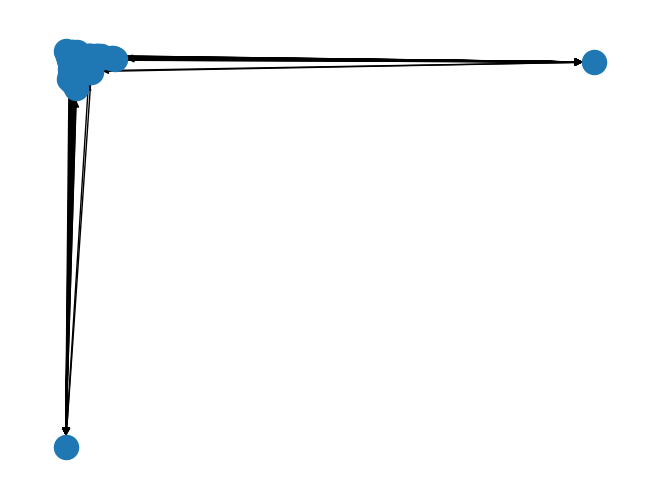

In [4]:
nx.draw_spectral(G)

In [3]:
nx.draw_networkx(G)

KeyboardInterrupt: 